In [9]:
import zipfile, os


zip_path = "/archive.zip"


extract_folder = "/content/data"
os.makedirs(extract_folder, exist_ok=True)


with zipfile.ZipFile(zip_path, "r") as z:
    z.extractall(extract_folder)

print("Extracted files:", os.listdir(extract_folder))


Extracted files: ['ecommerce_customer_data_custom_ratios.csv', 'ecommerce_customer_data_large.csv']


In [10]:
import pandas as pd


df = pd.read_csv("/content/data/ecommerce_customer_data_custom_ratios.csv")


df.head()


,Customer ID,Purchase Date,Product Category,Product Price,Quantity,Total Purchase Amount,Payment Method,Customer Age,Returns,Customer Name,Age,Gender,Churn
0,46251,2020-09-08 09:38:32,Electronics,12,3,740,Credit Card,37,0.0,Christine Hernandez,37,Male,0
1,46251,2022-03-05 12:56:35,Home,468,4,2739,PayPal,37,0.0,Christine Hernandez,37,Male,0
2,46251,2022-05-23 18:18:01,Home,288,2,3196,PayPal,37,0.0,Christine Hernandez,37,Male,0
3,46251,2020-11-12 13:13:29,Clothing,196,1,3509,PayPal,37,0.0,Christine Hernandez,37,Male,0
4,13593,2020-11-27 17:55:11,Home,449,1,3452,Credit Card,49,0.0,James Grant,49,Female,1


In [12]:
# Basic info
print("Shape:", df.shape)
print("\nColumns:\n", df.columns)
print("\nMissing values:\n", df.isnull().sum())
df.describe()


Shape: (250000, 13)

Columns:
 Index(['Customer ID', 'Purchase Date', 'Product Category', 'Product Price',
       'Quantity', 'Total Purchase Amount', 'Payment Method', 'Customer Age',
       'Returns', 'Customer Name', 'Age', 'Gender', 'Churn'],
      dtype='object')

Missing values:
 Customer ID                  0
Purchase Date                0
Product Category             0
Product Price                0
Quantity                     0
Total Purchase Amount        0
Payment Method               0
Customer Age                 0
Returns                  47596
Customer Name                0
Age                          0
Gender                       0
Churn                        0
dtype: int64


,Customer ID,Product Price,Quantity,Total Purchase Amount,Customer Age,Returns,Age,Churn
count,250000.00000,250000.000000,250000.000000,250000.000000,250000.000000,202404.000000,250000.000000,250000.000000
mean,25004.03624,254.659512,2.998896,2725.370732,43.940528,0.497861,43.940528,0.199496
std,14428.27959,141.568577,1.414694,1442.933565,15.350246,0.499997,15.350246,0.399622
min,1.00000,10.000000,1.000000,100.000000,18.000000,0.000000,18.000000,0.000000
25%,12497.75000,132.000000,2.000000,1477.000000,31.000000,0.000000,31.000000,0.000000
50%,25018.00000,255.000000,3.000000,2724.000000,44.000000,0.000000,44.000000,0.000000
75%,37506.00000,377.000000,4.000000,3974.000000,57.000000,1.000000,57.000000,0.000000
max,50000.00000,500.000000,5.000000,5350.000000,70.000000,1.000000,70.000000,1.000000


In [13]:
#Data Cleaning & Preprocessing
print("Duplicate rows:", df.duplicated().sum())


df = df.drop_duplicates()


df = df.dropna()


print("After cleaning:", df.shape)
df.head()


Duplicate rows: 0
After cleaning: (202404, 13)


,Customer ID,Purchase Date,Product Category,Product Price,Quantity,Total Purchase Amount,Payment Method,Customer Age,Returns,Customer Name,Age,Gender,Churn
0,46251,2020-09-08 09:38:32,Electronics,12,3,740,Credit Card,37,0.0,Christine Hernandez,37,Male,0
1,46251,2022-03-05 12:56:35,Home,468,4,2739,PayPal,37,0.0,Christine Hernandez,37,Male,0
2,46251,2022-05-23 18:18:01,Home,288,2,3196,PayPal,37,0.0,Christine Hernandez,37,Male,0
3,46251,2020-11-12 13:13:29,Clothing,196,1,3509,PayPal,37,0.0,Christine Hernandez,37,Male,0
4,13593,2020-11-27 17:55:11,Home,449,1,3452,Credit Card,49,0.0,James Grant,49,Female,1


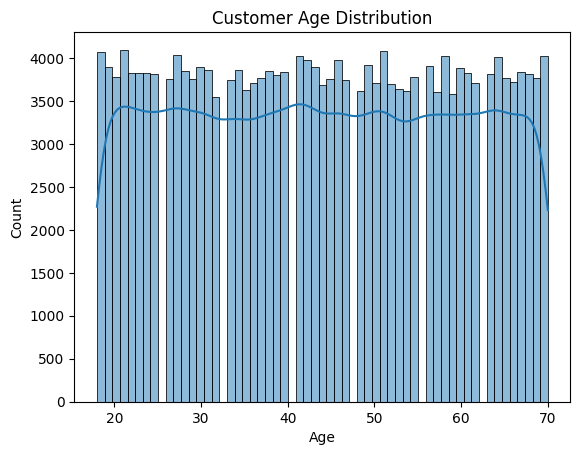

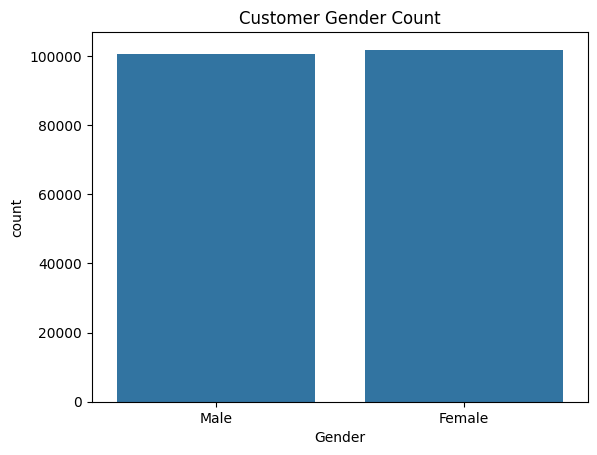

In [14]:
#Basic distributions

import matplotlib.pyplot as plt
import seaborn as sns


sns.histplot(df['Age'], kde=True)
plt.title("Customer Age Distribution")
plt.show()


sns.countplot(x='Gender', data=df)
plt.title("Customer Gender Count")
plt.show()


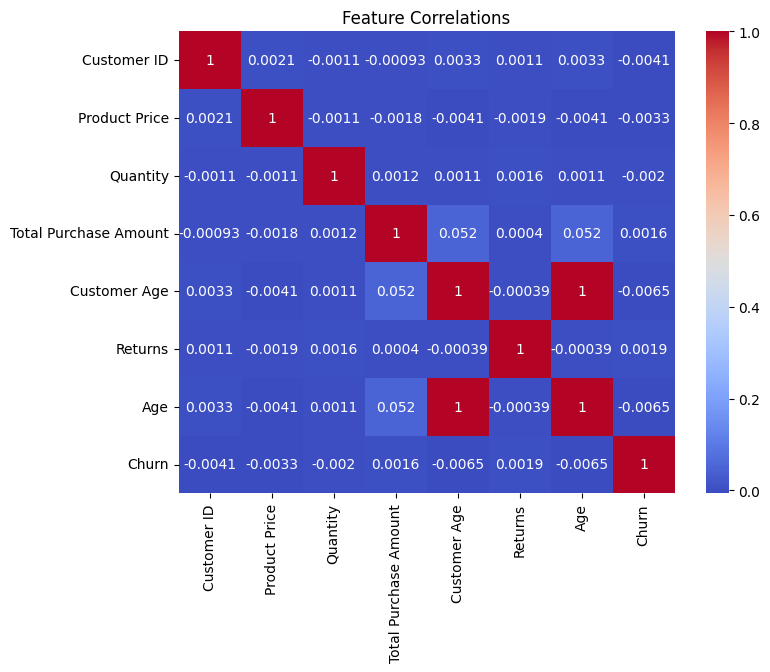

In [16]:
#Correlation heatmap
plt.figure(figsize=(8,6))
sns.heatmap(df.corr(numeric_only=True), annot=True, cmap="coolwarm")
plt.title("Feature Correlations")
plt.show()


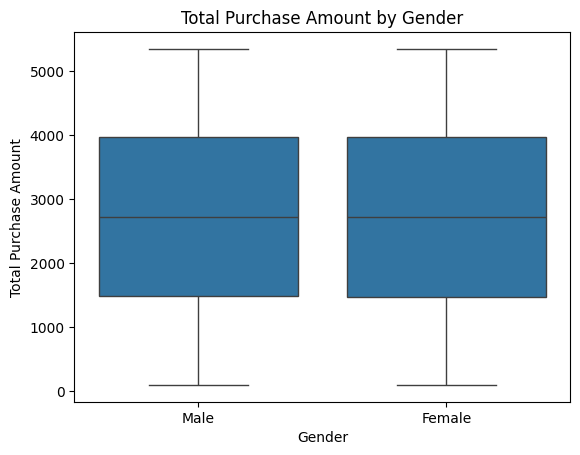

In [19]:
#Boxplot — Spending by Gender
sns.boxplot(x='Gender', y='Total Purchase Amount', data=df)
plt.title("Total Purchase Amount by Gender")
plt.show()


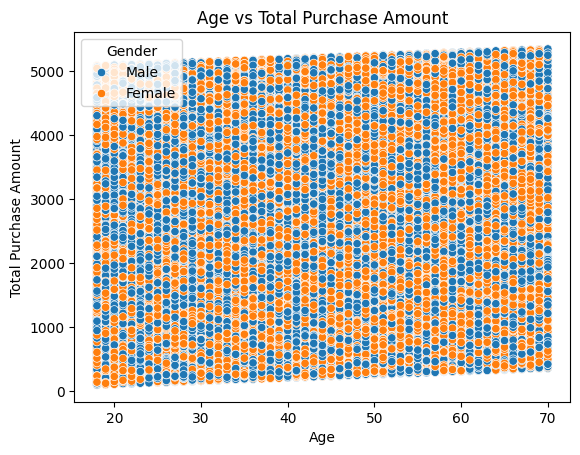

In [20]:
#Scatter Plot — Age vs. Total Purchase Amount

sns.scatterplot(x='Age', y='Total Purchase Amount', hue='Gender', data=df)
plt.title("Age vs Total Purchase Amount")
plt.show()


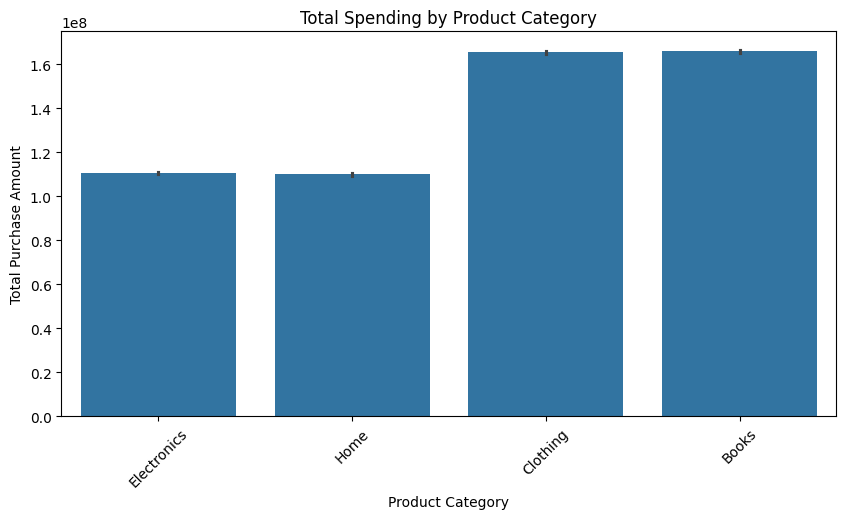

In [21]:
#Category-wise Spending
plt.figure(figsize=(10,5))
sns.barplot(x='Product Category', y='Total Purchase Amount', data=df, estimator=sum)
plt.title("Total Spending by Product Category")
plt.xticks(rotation=45)
plt.show()


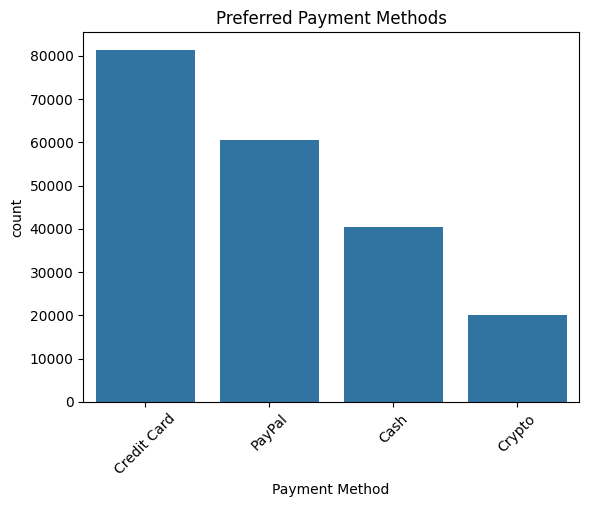

In [22]:
#Payment Method Preference
sns.countplot(x='Payment Method', data=df)
plt.title("Preferred Payment Methods")
plt.xticks(rotation=45)
plt.show()
